# Versión 2: incorporar historia y recuperar Temuco y Padre Las Casas

Clasificación supervisada de crecimiento de al menos 1% anual. Proyecto individual tutorado con Pablo Valenzuela. **2024 ya se observó en v1**: esta versión produce una reevaluación temporal exploratoria, no una prueba final nueva e independiente. La primera prueba se conserva sin reemplazar sus datos ni resultados.

## 1. Hipótesis y protocolo

Población y edades de un único censo no capturaron suficientemente la dinámica demográfica. Se añade crecimiento anterior y se comparan alternativas con cambios en las proporciones de edad. Se conserva el umbral de 1%. La ampliación nace del diagnóstico de v1, que ya incluyó 2024. La elección mecánica de esta nueva configuración no usa etiquetas de 2024; después de la reevaluación v2 no se cambian parámetros para subir ese resultado.

Entradas de entrenamiento: censos 1992 y 2002; respuesta: crecimiento 2002–2017. Selección: cinco particiones de las 314 comunas de esa etapa. Cada ejemplo se predice sin estar en el ajuste de su partición. Se elige por media de F1 macro, exactitud balanceada y simplicidad. Diez candidatos se registraron antes de entrenar v2. Esta CV es entre comunas de una época; no demuestra generalización a futuros períodos.

In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import joblib
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import export_text
from IPython.display import display,Image
ROOT=Path.cwd()
if not (ROOT/'experiments').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'experiments'))
import crecimiento_v2 as v2
import crecimiento_censal as v1
OUT=v2.OUT
protocol=json.loads(v2.PROTOCOL.read_text())
summary=json.loads((OUT/'resumen.json').read_text())
quality=json.loads((OUT/'calidad_datos.json').read_text())
closed=json.loads((OUT/'seleccion_cerrada.json').read_text())
profiles=pd.read_csv(OUT/'perfiles_censales.csv')
core=summary['core_codes']
print('Selección usa etiquetas de 2024:',closed['selection_used_2024_labels'])
print('2024 conocido en v1:',closed['2024_seen_in_v1'])
print('Clasificador seleccionado:',closed['selected'])

Selección usa etiquetas de 2024: False
2024 conocido en v1: True
Clasificador seleccionado: bosque_tendencia


## 2. Recuperación geográfica y procedencia

La exclusión inicial fue conservadora. REDATAM ya publica Temuco y Padre Las Casas por separado en 1992. La Ley 19.391 creó Padre Las Casas en 1995; que exista una tabla retrospectiva no significa que existiera jurídicamente en 1992.

El INE comunicó el 12-09-2018 que actualizó las bases y REDATAM de 2002 a la nueva división administrativa. La Ley 20.578 trasladó un sector desde Freire a Padre Las Casas en 2012. Se utiliza la publicación actual de 2002, no se suman personas de San Ramón manualmente. **1992 se excluye de la historia usada para Padre Las Casas** porque no se acredita su ajuste al traspaso posterior. Su clasificación histórica usa 2002 y 2017; el escenario futuro usa 2017 y 2024.

La recuperación es preliminar y falta una auditoría cartográfica exhaustiva. Las dos comunas quedan fuera del ajuste y selección históricos, y se presentan como aplicaciones adicionales. La comparación v1/v2 mantiene las 314 originales.

In [2]:
sources=json.loads((ROOT/'data/raw/ine/crecimiento/fuentes.json').read_text())
territorial=json.loads((ROOT/'data/raw/ine/crecimiento/fuentes_territoriales_v2.json').read_text())
display(pd.DataFrame(sources['files'])[['file','bytes','sha256']])
display(pd.DataFrame(territorial['files'])[['file','url','bytes','sha256']])
display(pd.DataFrame(quality['recovered']))
display(profiles.loc[profiles.code.isin([9101,9112]),['name','year','population','young','old']])
print('Contraste independiente 2017:',quality['independent_2017_check'])
assert set(profiles.year)=={1992,2002,2017,2024}
assert profiles.loc[(profiles.code==9112)&(profiles.year==1992)].empty

,file,bytes,sha256
0,edad_residencia_1992.html,397439,a6dd2b414fb0466bec4519d698d56216e40dd1ebb6fc3a...
1,edad_residencia_2002.html,347336,24212f5052fd331bd7135846af70c1847482e48a9f9d82...
2,edad_residencia_2017.html,306826,efa35d98f0ee8522f809f9d19638d75e59b3b354a44c3d...
3,edad_local_2017.html,262995,996b8f65fac8ed7a81862c81459f768af0d3c9686d4447...
4,poblacion_2024.xlsx,505437,1f3a9c97a1b3defa47a2fc3b8495688c4e08f164063cab...
5,residentes_2017.xlsx,69970,ea5aa0f3a1bad6acce93252e7f1e590f11dd721d1331eb...


,file,url,bytes,sha256
0,actualizacion_dpa_ine_2018.html,https://www.ine.gob.cl/sala-de-prensa/prensa/g...,97736,d9da752897df7c96a962dd27da6e9e53a4ff8bfde6cf88...
1,diccionario_2002.html,https://redatam-ine.ine.cl/redbin/RpWebStats.e...,32141,d2d6f9b78462ce09cdc171914e8ea4d79696d9647accfc...
2,antecedentes_limites_mma_2015.pdf,https://airechile.mma.gob.cl/download/DO-PDA-T...,1862993,12e016e2eb1d03f64bd5b2b1304ec1d1396c5851883719...


,code,name,usable_years,note
0,9101,Temuco,"[1992, 2002, 2017, 2024]",La tabla REDATAM de 1992 ya identifica Temuco ...
1,9112,Padre Las Casas,"[2002, 2017, 2024]",No se utiliza 1992 en su historia. Se usa el t...


,name,year,population,young,old
942,Temuco,1992,197751,55919,11962
943,Temuco,2002,246349,62091,17771
944,Temuco,2017,280295,54926,30071
945,Padre Las Casas,2002,59437,16936,4185
946,Padre Las Casas,2017,74911,17083,7268
1173,Temuco,2024,292518,50846,38842
1182,Padre Las Casas,2024,80656,15982,10001


Contraste independiente 2017: {'compared_communes': 346, 'differences': []}


## 3. Datos, variables y preparación

Unidad: comuna-período; habitantes no son muestras independientes. La población es un recuento de razón; las proporciones y tasas son numéricas. Identificadores y nombres son nominales y quedan fuera de las entradas. Se trabaja con residentes habituales con comuna identificada. En 2017 no equivale al total de personas censadas físicamente en una comuna: Padre Las Casas tiene 74.911 residentes identificados en la tabla utilizada, frente a 76.126 censados allí. Cobertura y no respuesta afectan la comparación.

Se calculan seis posibles entradas. Los cambios de proporción se dividen por la duración anterior. El Random Forest elegido usa cuatro: logaritmo de población, menores de 15, 65 o más y crecimiento anterior. El escalado de las alternativas de Logistic Regression ocurre dentro de cada partición mediante Pipeline. No se mezcla la población final con las entradas, ni se utilizan cifras de 2012 o proyecciones como observaciones.

In [3]:
display(profiles.groupby('year').agg(comunas=('code','nunique'),residentes=('population','sum')))
initial,X,y_previous=v2.inputs(profiles,1992,2002,core)
y,_,_=v2.labels(profiles,2002,2017,core)
display(X.describe().T)
print('Clases de respuesta:',np.bincount(y),'filas:',len(X))
display(X.head())
print('Entradas seleccionadas:',closed['candidate']['features'])

,comunas,residentes
year,,
1992,315,11171717
2002,316,12499266
2017,316,14351217
2024,316,15340117


,count,mean,std,min,25%,50%,75%,max
log_poblacion,314.0,9.706873,1.406373,3.332205,8.992649,9.667013,10.547774,13.055929
proporcion_menores_15,314.0,0.265654,0.032861,0.035971,0.256264,0.269921,0.281736,0.370370
proporcion_65_mas,314.0,0.089163,0.023676,0.000000,0.076387,0.089787,0.103478,0.170817
crecimiento_previo,314.0,0.007097,0.018667,-0.133380,-0.001900,0.005980,0.015024,0.118767
cambio_menores_15_anual,314.0,-0.003861,0.001943,-0.017138,-0.004602,-0.003841,-0.003102,0.013143
cambio_65_mas_anual,314.0,0.001808,0.001000,-0.001420,0.001261,0.001782,0.002330,0.005495


Clases de respuesta: [217  97] filas: 314


,log_poblacion,proporcion_menores_15,proporcion_65_mas,crecimiento_previo,cambio_menores_15_anual,cambio_65_mas_anual
code,,,,,,
1401,9.149316,0.298395,0.064208,0.042421,-0.004836,0.000043
1402,7.160846,0.363636,0.097125,-0.009786,-0.003284,0.003445
1403,7.296413,0.318182,0.110583,-0.005271,-0.012390,0.004688
1404,7.833204,0.293814,0.115781,0.027061,-0.000707,-0.001420
1405,8.160232,0.257576,0.108919,0.041380,-0.003874,0.000300


Entradas seleccionadas: ['log_poblacion', 'proporcion_menores_15', 'proporcion_65_mas', 'crecimiento_previo']


## 4. Entrenamiento y validación reproducidos

Se muestran todos los candidatos, incluidos aquellos que no mejoraron. La media por partición determina la selección. El F1 conjunto de predicciones fuera del ajuste es una métrica descriptiva distinta; no se reemplaza el criterio de selección por ella. Se reproduce aquí la CV del candidato elegido, utilizando únicamente respuestas hasta 2017. La elección está guardada antes de reevaluar 2024.

In [4]:
display(pd.read_csv(OUT/'comparacion_validacion.csv').sort_values('selection_f1_mean',ascending=False))
folds=StratifiedKFold(n_splits=5,shuffle=True,random_state=2025)
predictions=np.zeros(len(y),dtype=int)
fold_f1=[]
for train,valid in folds.split(X,y):
    classifier=v2.make_model(closed['candidate']).fit(X.iloc[train],y[train])
    predictions[valid]=classifier.predict(X.iloc[valid])
    fold_f1.append(v1.metrics(y[valid],predictions[valid])['f1_macro'])
assert np.isclose(np.mean(fold_f1),summary['validation'][closed['selected']]['selection_f1_mean'])
print('F1 medio reproducido:',np.mean(fold_f1),'F1 conjunto:',v1.metrics(y,predictions)['f1_macro'])
historical=v2.make_model(closed['candidate']).fit(X,y)
initial_test,X_test,old=v2.inputs(profiles,2002,2017,sorted(core+[9101,9112]))
saved=joblib.load(OUT/'clasificador_historico.joblib')
np.testing.assert_allclose(historical.predict_proba(X_test),saved.predict_proba(X_test))
print('Ajuste histórico reproducido con 314 respuestas hasta 2017')

,model,algorithm,features,selection_f1_mean,selection_f1_std,f1_macro,accuracy
8,bosque_tendencia,RandomForestClassifier,4,0.761795,0.052000,0.761607,0.789809
6,logistica_tendencia,LogisticRegression,4,0.758164,0.049058,0.758114,0.780255
1,bosque_d5,RandomForestClassifier,6,0.748418,0.029309,0.748397,0.777070
9,arbol_d2,DecisionTreeClassifier,6,0.729455,0.053495,0.730069,0.754777
5,arbol_tendencia,DecisionTreeClassifier,4,0.729201,0.018958,0.729369,0.745223
0,arbol_d3,DecisionTreeClassifier,6,0.718175,0.021358,0.718724,0.738854
2,logistica_c0.1,LogisticRegression,6,0.702631,0.027424,0.703614,0.732484
3,logistica_c1,LogisticRegression,6,0.696871,0.029339,0.697874,0.726115
4,logistica_c10,LogisticRegression,6,0.696857,0.027674,0.697874,0.726115
7,bosque_sin_historia,RandomForestClassifier,3,0.567448,0.035381,0.571230,0.621019


F1 medio reproducido: 0.7617946886333256 F1 conjunto: 0.7616067731100171


Ajuste histórico reproducido con 314 respuestas hasta 2017


## 5. Reevaluación temporal exploratoria

El Random Forest elegido obtiene 205 aciertos de 314 y F1 macro 0,642. V1 obtuvo 169 y 0,528. La continuidad anterior mantiene 213 y 0,663. **Se mejoró frente a v1, pero no se supera la referencia práctica.** El Random Forest detecta 130 de las 150 comunas con crecimiento alto, frente a 73 de continuidad; produce 89 falsas alertas frente a 24. Esa diferencia puede interesar para revisar casos, sin acreditar superioridad general o utilidad futura. Las dos comunas recuperadas no se añaden al denominador para presentar una mejora artificial.

El remuestreo pareado de regiones produce un intervalo exploratorio de diferencia de F1 que contiene cero. No acredita una ventaja clara. La variación temporal, las duraciones y la geografía limitan la inferencia; 2024 sigue siendo una reevaluación de datos ya conocidos.

,alternativa,n,f1_macro,balanced_accuracy,accuracy
0,modelo,314,0.641879,0.661992,0.652866
1,persistencia,314,0.663001,0.670163,0.678344
2,mayoria,314,0.343096,0.500000,0.522293
3,v1,314,0.527633,0.532602,0.538217


,Predice <1%,Predice ≥1%
Real <1%,75,89
Real ≥1%,20,130


,precision,recall,f1-score,support
Menor que 1% anual,0.789474,0.457317,0.579151,164.000000
Al menos 1% anual,0.593607,0.866667,0.704607,150.000000
accuracy,0.652866,0.652866,0.652866,0.652866
macro avg,0.691540,0.661992,0.641879,314.000000
weighted avg,0.695907,0.652866,0.639082,314.000000


Comparación pareada: {'method': 'Bootstrap pareado por región, 1000 réplicas; intervalo exploratorio', 'delta_f1_macro': -0.021121814335403277, 'interval_95': [-0.11311698081783347, 0.09085080341697105], 'new_correct_baseline_wrong': 58, 'new_wrong_baseline_correct': 66}


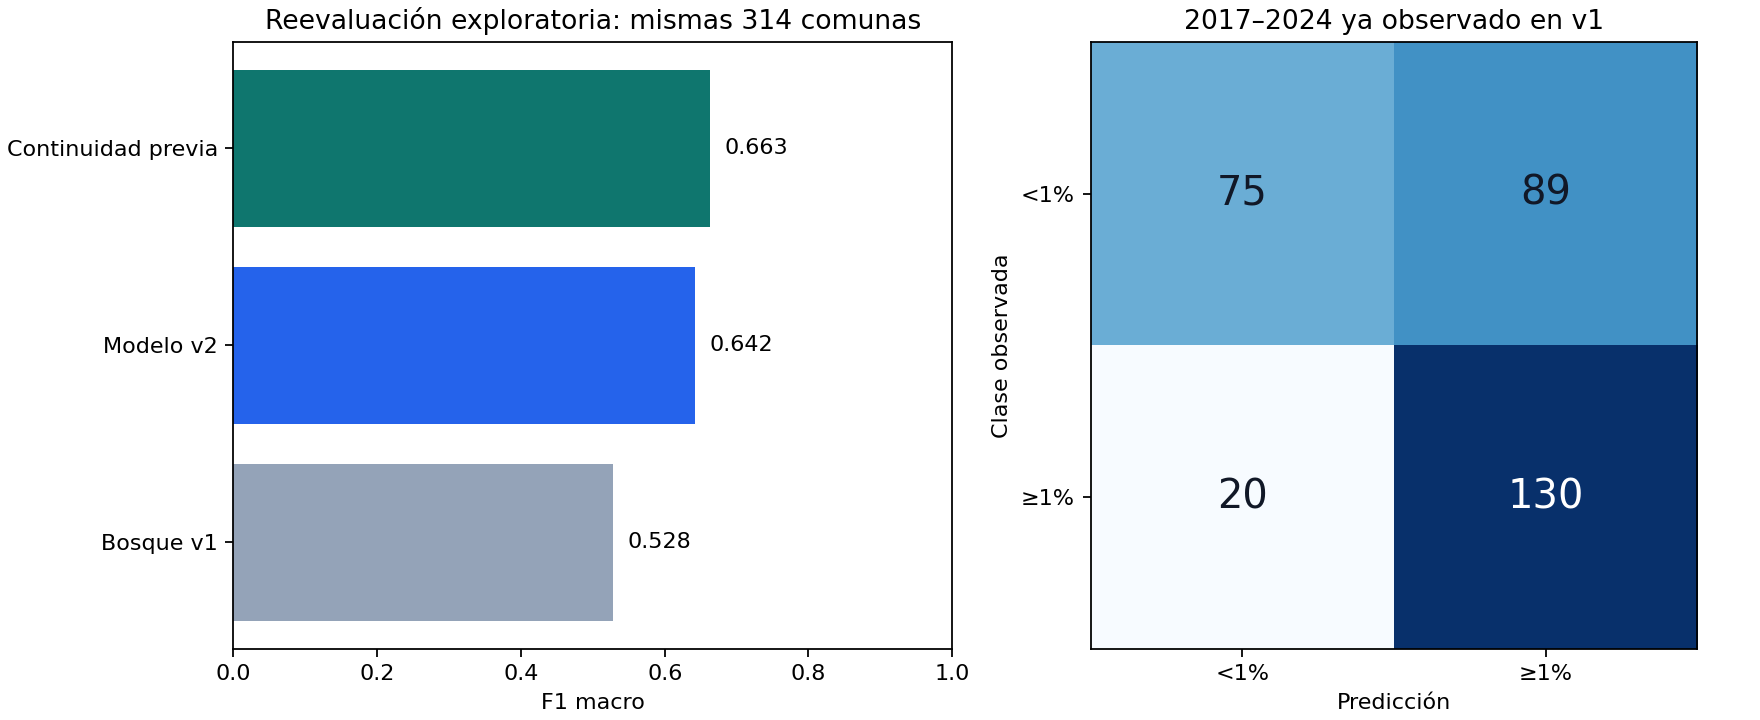

,name,population,previous_population,previous_rate,actual_population,actual_rate,predicted_class,actual_class,correct
155,Temuco,280295,246349,0.008643,292518,0.006116,1,0,False
164,Padre Las Casas,74911,59437,0.015545,80656,0.010612,1,1,True


In [5]:
display(pd.DataFrame([{'alternativa':k,**{metric:r[metric] for metric in ('n','f1_macro','balanced_accuracy','accuracy')}} for k,r in summary['test'].items()]))
display(pd.DataFrame(summary['test']['modelo']['confusion'],index=['Real <1%','Real ≥1%'],columns=['Predice <1%','Predice ≥1%']))
display(pd.DataFrame(summary['test']['modelo']['classes']).T)
print('Comparación pareada:',summary['paired_vs_persistence'])
display(Image(filename=str(OUT/'evaluacion.png')))
individual=pd.read_csv(OUT/'predicciones_historicas.csv')
display(individual.loc[individual.code.isin([9101,9112]),['name','population','previous_population','previous_rate','actual_population','actual_rate','predicted_class','actual_class','correct']])

## 6. Modelo futuro separado y utilidad de la aplicación

El escenario 2024–2031 utiliza el mismo diseño elegido, pero un ajuste distinto con 630 ejemplos: 314 de 2002–2017 y 316 de 2017–2024. Puede usar respuestas de 2024 porque ese resultado ya se conoce al emitir el escenario. El modelo histórico se conserva por separado, sin esas respuestas en su entrenamiento. No existe aún un resultado de 2031; su precisión futura no está demostrada.

La aplicación entrega clasificación y continuidad anterior juntas. Si difieren, muestra la discrepancia; si coinciden, no la presenta como garantía. Permite revelar el resultado histórico, consultar ambas comunas y examinar procedencia. El puntaje interno no es una probabilidad calibrada.

In [6]:
y_later,_,_=v2.labels(profiles,2017,2024,sorted(core+[9101,9112]))
future=v2.make_model(closed['candidate']).fit(pd.concat([X,X_test]),np.concatenate([y,y_later]))
latest,future_X,_=v2.inputs(profiles,2017,2024,sorted(core+[9101,9112]))
saved_future=joblib.load(OUT/'clasificador_futuro.joblib')
np.testing.assert_allclose(future.predict_proba(future_X),saved_future.predict_proba(future_X))
print('Ajuste futuro reproducido:',len(X)+len(X_test),'ejemplos; no hay respuesta observada de 2031')
print('Importancias del modelo futuro:',summary['explanation'])
print('Un árbol de los 300 del modelo histórico, como ejemplo didáctico:')
print(export_text(saved.named_steps['classifier'].estimators_[0],feature_names=closed['candidate']['features'],max_depth=2))

Ajuste futuro reproducido: 630 ejemplos; no hay respuesta observada de 2031
Importancias del modelo futuro: {'kind': 'Importancia interna de particiones; no es importancia causal.', 'values': {'log_poblacion': 0.09463931948818022, 'proporcion_menores_15': 0.1638678534887999, 'proporcion_65_mas': 0.17791357208667388, 'crecimiento_previo': 0.5635792549363461}}
Un árbol de los 300 del modelo histórico, como ejemplo didáctico:
|--- crecimiento_previo <= 0.01
|   |--- proporcion_65_mas <= 0.09
|   |   |--- proporcion_65_mas <= 0.08
|   |   |   |--- truncated branch of depth 3
|   |   |--- proporcion_65_mas >  0.08
|   |   |   |--- truncated branch of depth 3
|   |--- proporcion_65_mas >  0.09
|   |   |--- proporcion_menores_15 <= 0.23
|   |   |   |--- class: 1.0
|   |   |--- proporcion_menores_15 >  0.23
|   |   |   |--- truncated branch of depth 2
|--- crecimiento_previo >  0.01
|   |--- log_poblacion <= 9.97
|   |   |--- log_poblacion <= 9.01
|   |   |   |--- class: 1.0
|   |   |--- log_p

## Fuentes y límites académicos

- [INE: censos y REDATAM](https://www.ine.gob.cl/estadisticas-por-tema/demografia-y-poblacion/censo-de-poblacion-y-vivienda).
- [INE: actualización de DPA de 2002 y 2017, 12-09-2018](https://www.ine.gob.cl/sala-de-prensa/prensa/general/noticia/2019/09/16/ine-actualiza-informaci%C3%B3n-de-censo-2017-a-la-nueva-divisi%C3%B3n-pol%C3%ADtica-administrativa-incorporando-la-nueva-regi%C3%B3n-de-%C3%B1uble).
- [Ley 19.391](https://www.bcn.cl/leychile/Navegar?idNorma=30758) y [Ley 20.578](https://www.bcn.cl/leychile/navegar?idNorma=1038291).
- [MMA: documento territorial de 2015](https://airechile.mma.gob.cl/download/DO-PDA-Temuco-y-Padre-Las-%20Casas.pdf), usado como antecedente de límites, sin cifras de 2012 para el modelo.

Atribución INE: tabulados y derivados censales bajo CC BY-SA 4.0, transformaciones documentadas. La recuperación cartográfica es preliminar. La revisión académica y calendario individual con Pablo Valenzuela quedan por acordar. No se ha enviado una comunicación al profesor.